In [1]:
%pip install opencv-python


   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ------------ --------------------------- 13.9/44.0 MB 65.6 MB/s eta 0:00:01
   ------------------------- -------------- 27.5/44.0 MB 66.1 MB/s eta 0:00:01
   ----------------------------------- ---- 39.1/44.0 MB 63.0 MB/s eta 0:00:01
   ---------------------------------------- 44.0/44.0 MB 57.5 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


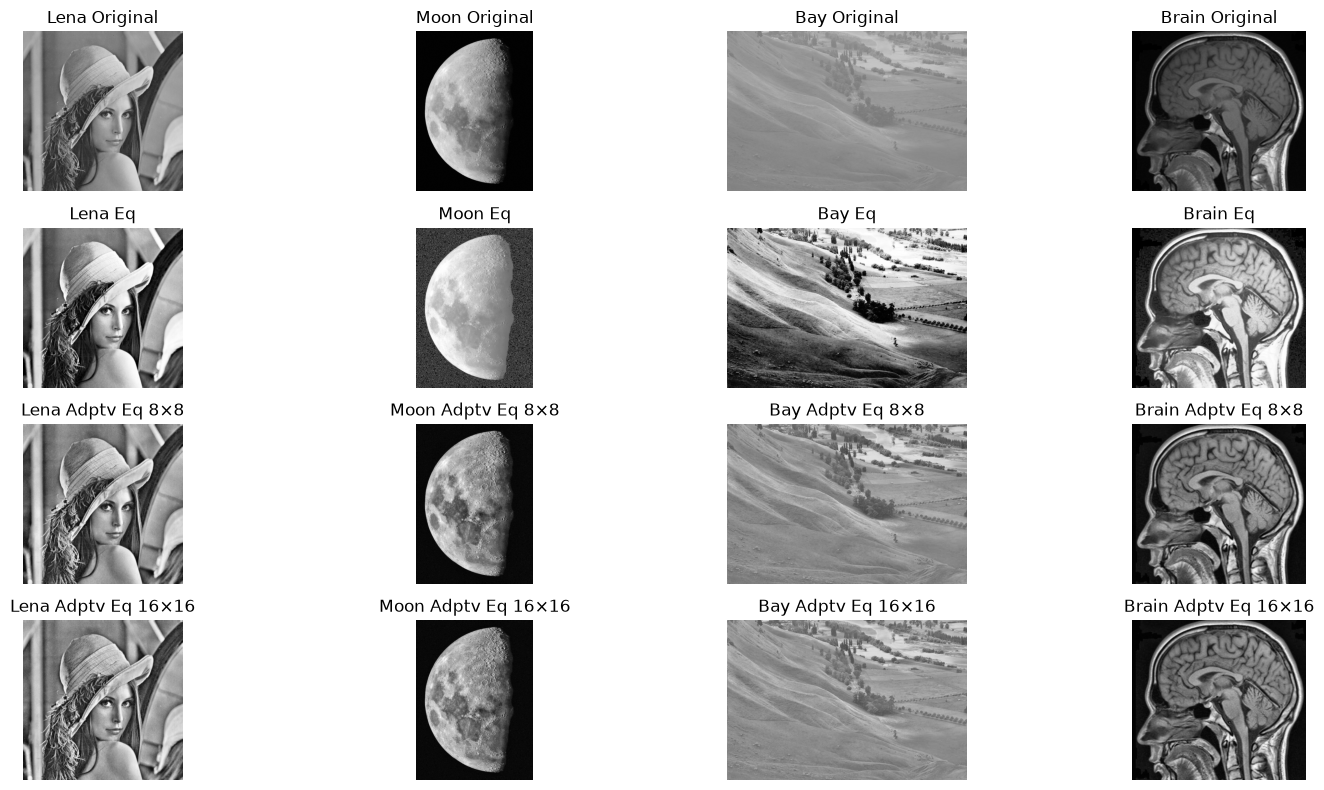

In [26]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import cv2

Lena = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")
Moon = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/moon.jpg")
Bay = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/bay.jpg")
Brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

with urlopen(Lena) as response:
    lena = Image.open(BytesIO(response.read())) 
with urlopen(Moon) as response:
    moon = Image.open(BytesIO(response.read())) 
with urlopen(Bay) as response:
    bay = Image.open(BytesIO(response.read()))  
with urlopen(Brain) as response:
    brain = Image.open(BytesIO(response.read()))

images = {"Lena": lena,"Moon": moon,"Bay": bay,"Brain": brain,}
histograms = {}
equalized_histograms = {}
equalized_images = {}
adaptive_equalized_images = {(8, 8): {},(16, 16): {},}
adaptive_equalized_histograms = {(8, 8): {},(16, 16): {},}

tile_grids = [(8, 8), (16, 16)]

fig, axes = plt.subplots(4, len(images), figsize=(4 * len(images), 8), squeeze=False)

for col, (name, image) in enumerate(images.items()):
    pixels = np.asarray(image, dtype=np.uint8)
 
    histogram, _ = np.histogram(pixels.ravel(), bins=256, range=(0, 256))

    pxl_ntst = histogram.cumsum()
    pxl_ntst_min = pxl_ntst[pxl_ntst > 0][0]

    if pxl_ntst_min == pixels.size:  
        equalized_pixels = pixels.copy()
    else:
        lookup_table = np.rint((pxl_ntst - pxl_ntst_min) * 255 / (pixels.size - pxl_ntst_min)).clip(0, 255).astype(np.uint8)
        equalized_pixels = lookup_table[pixels]

    equalized_images[name] = Image.fromarray(equalized_pixels)

    for row, tile_grid in enumerate(tile_grids, start=2):
        clahe = cv2.createCLAHE(clipLimit=2.0,tileGridSize=tile_grid,)
        adaptive_equalized_pixels = clahe.apply(pixels)

        adaptive_equalized_images[tile_grid][name] = Image.fromarray(adaptive_equalized_pixels)
        adaptive_equalized_histograms[tile_grid][name], _ = np.histogram(adaptive_equalized_pixels.ravel(), bins=256, range=(0, 256))

        axes[0, col].imshow(pixels, cmap="gray", vmin=0, vmax=255)
        axes[0, col].set_title(f"{name} Original")
        axes[0, col].axis("off")
        
        axes[1, col].imshow(equalized_pixels, cmap="gray", vmin=0, vmax=255)
        axes[1, col].set_title(f"{name} Eq")
        axes[1, col].axis("off")
        
        axes[row, col].imshow(adaptive_equalized_pixels, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{name} Adptv Eq {tile_grid[0]}×{tile_grid[1]}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()